# Delhi AQI — EDA, Feature Engineering & AQI Construction

This notebook works through the `final_delhi_dataset.csv` file:

1. **Load & understand the data** — structure, coverage, missingness
2. **Exploratory Data Analysis (EDA)** — distributions, trends, seasonality, station comparison, correlations
3. **Build an `AQI` target column** from raw pollutant concentrations using the official **CPCB (Central Pollution Control Board, India) National AQI** formula
4. **Feature engineering** — time features, lag features, rolling-window features, rate-of-change features
5. **Assemble a model-ready dataset** and show a correct (leakage-free) train/test split for forecasting

> Run cells top to bottom. Each section is self-contained and builds on the previous one.

## 1. Setup & Load Data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.max_columns', None)

DATA_PATH = 'final delhi dataset.csv' 
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (175320, 28)


,timestamp,PM25,PM10,NO,NO2,NOx,NH3,SO2,CO,O3,Benzene,Toluene,Xylene,O_Xylene,Eth_Benzene,MP_Xylene,temperature,humidity,wind_speed,wind_direction,rainfall,total_rainfall,solar_radiation,pressure,vertical_wind_speed,source_file,station,city
0,2022-01-01 00:00:00,613.25,NaN,406.70,104.50,387.18,30.1,17.80,NaN,5.38,NaN,134.38,NaN,NaN,NaN,NaN,11.95,84.15,0.3,173.00,NaN,0.0,8.95,974.98,NaN,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi
1,2022-01-01 01:00:00,684.00,892.0,313.38,73.82,294.77,68.2,10.95,NaN,0.30,NaN,123.12,NaN,NaN,NaN,NaN,11.52,87.62,0.3,220.50,NaN,0.0,8.88,974.90,NaN,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi
2,2022-01-01 02:00:00,615.25,916.5,357.10,66.70,325.20,NaN,8.80,NaN,6.75,NaN,121.08,NaN,NaN,NaN,NaN,11.38,89.38,0.3,215.75,NaN,0.0,8.88,974.78,NaN,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi
3,2022-01-01 03:00:00,739.00,950.0,289.58,70.25,273.48,64.4,5.67,NaN,6.90,NaN,109.78,NaN,NaN,NaN,NaN,11.15,90.65,0.3,201.75,NaN,0.0,8.90,974.90,NaN,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi
4,2022-01-01 04:00:00,596.50,801.5,233.18,60.12,222.10,NaN,12.28,NaN,10.20,14.87,92.15,NaN,NaN,NaN,NaN,11.05,91.32,0.3,222.00,NaN,0.0,8.88,974.68,NaN,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175320 entries, 0 to 175319
Data columns (total 28 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   timestamp            175320 non-null  str    
 1   PM25                 165937 non-null  float64
 2   PM10                 165376 non-null  float64
 3   NO                   164970 non-null  float64
 4   NO2                  164281 non-null  float64
 5   NOx                  165587 non-null  float64
 6   NH3                  131815 non-null  float64
 7   SO2                  128722 non-null  float64
 8   CO                   162896 non-null  float64
 9   O3                   166224 non-null  float64
 10  Benzene              137883 non-null  float64
 11  Toluene              104479 non-null  float64
 12  Xylene               28194 non-null   float64
 13  O_Xylene             0 non-null       float64
 14  Eth_Benzene          0 non-null       float64
 15  MP_Xylene            688 non

## 2. First Look at the Data

Quick facts worth knowing before doing anything else:
- The data is **hourly** pollutant + weather readings from **5 Delhi monitoring stations**, from **2022-01-01 to 2025-12-31**.
- Each station has exactly **35,064 rows** — that's `4 years x 365.25 x 24`, so the timestamp grid is already complete (no missing *rows*, only missing *values* within existing rows).
- Some columns (`O_Xylene`, `Eth_Benzene`, `MP_Xylene`) are essentially 100% empty and add nothing — we'll drop them.

In [10]:
print("Stations:", df['station'].unique())
print()
print("Date range:", df['timestamp'].min(), "to", df['timestamp'].max())
print()
print("Rows per station:")
print(df['station'].value_counts())

Stations: <StringArray>
['Anand Vihar', 'Dwarka Sector 8', 'IMD Lodhi Road', 'ITO', 'Punjabi Bagh']
Length: 5, dtype: str

Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00

Rows per station:
station
Anand Vihar        35064
Dwarka Sector 8    35064
IMD Lodhi Road     35064
ITO                35064
Punjabi Bagh       35064
Name: count, dtype: int64


In [11]:
# Missingness overview, sorted worst to best
missing_pct = df.isna().mean().sort_values(ascending=False) * 100
missing_pct.to_frame('missing_%')

,missing_%
Eth_Benzene,100.000000
O_Xylene,100.000000
MP_Xylene,99.607575
Xylene,83.918549
vertical_wind_speed,80.488820
rainfall,80.232717
pressure,53.421173
wind_direction,42.169747
wind_speed,42.119553
solar_radiation,42.052818


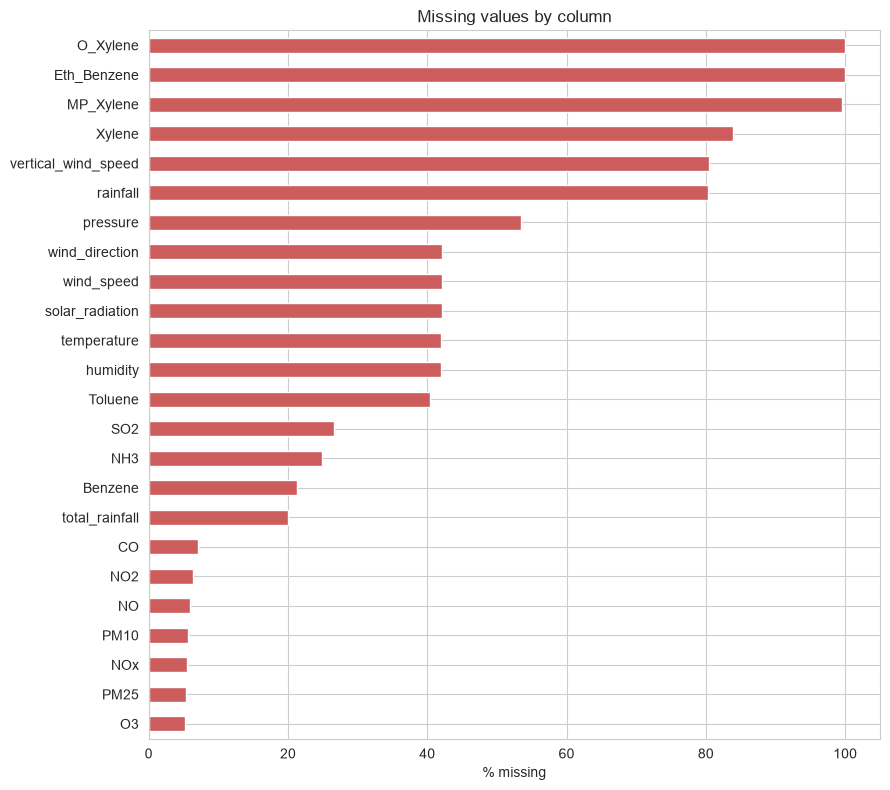

In [12]:
fig, ax = plt.subplots(figsize=(9, 8))
missing_pct[missing_pct > 0].sort_values().plot(kind='barh', ax=ax, color='indianred')
ax.set_xlabel('% missing')
ax.set_title('Missing values by column')
plt.tight_layout()
plt.show()

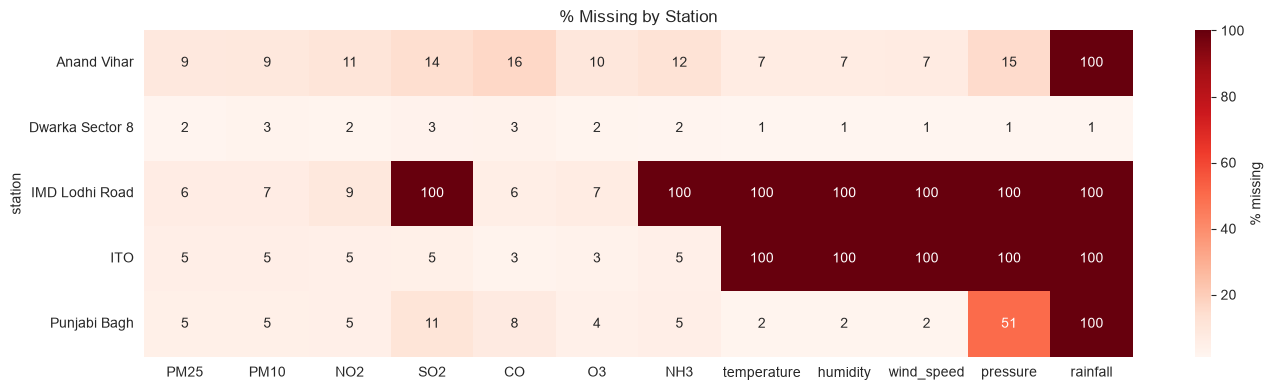

In [13]:
# Missingness varies a lot by station — worth checking before imputing anything
station_missing = df.groupby('station').apply(lambda x: x.isna().mean() * 100)
cols_to_check = ['PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3',
                  'temperature', 'humidity', 'wind_speed', 'pressure', 'rainfall']

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(station_missing[cols_to_check], annot=True, fmt='.0f', cmap='Reds', ax=ax, cbar_kws={'label': '% missing'})
ax.set_title('% Missing by Station')
plt.tight_layout()
plt.show()

**Key observation:** `IMD Lodhi Road` and `ITO` have **~100% missing weather data** (temperature, humidity, wind speed, pressure, solar radiation), while the other three stations have relatively good weather coverage. This tells us the weather sensors were only co-located with some monitoring stations. Keep this in mind:
- Pollutant-only features will work for all 5 stations.
- Weather-based features will effectively be `NaN` for `IMD Lodhi Road` and `ITO` unless imputed from another source (e.g. a city-wide weather average).

In [14]:
# Drop columns that are (near) entirely empty and add no information
cols_to_drop = ['O_Xylene', 'Eth_Benzene', 'MP_Xylene','rainfall','Xylene','vertical_wind_speed']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print("Shape after dropping empty:", df.shape)

Shape after dropping empty: (175320, 22)


## 3. Timestamp Handling & Continuity Check

We parse the timestamp and sort by `station` + `timestamp`. We then confirm there are no *gaps* in the hourly grid — important, because lag/rolling features assume "1 row back" really means "1 hour back".

In [15]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['station', 'timestamp']).reset_index(drop=True)

# confirm each station's timestamp index has no gaps
for station, g in df.groupby('station'):
    full_range = pd.date_range(g['timestamp'].min(), g['timestamp'].max(), freq='h')
    n_gaps = len(full_range) - len(g)
    print(f"{station:20s} rows={len(g):6d}  expected={len(full_range):6d}  gaps={n_gaps}")

Anand Vihar          rows= 35064  expected= 35064  gaps=0
Dwarka Sector 8      rows= 35064  expected= 35064  gaps=0
IMD Lodhi Road       rows= 35064  expected= 35064  gaps=0
ITO                  rows= 35064  expected= 35064  gaps=0
Punjabi Bagh         rows= 35064  expected= 35064  gaps=0


## 4. Univariate EDA — Pollutant Distributions

Delhi's pollutant levels are heavily right-skewed with a long tail of extreme pollution events (winter smog episodes). We clip at the 99th percentile purely for plotting so a handful of extreme outliers don't crush the histogram — the raw data itself is left untouched.

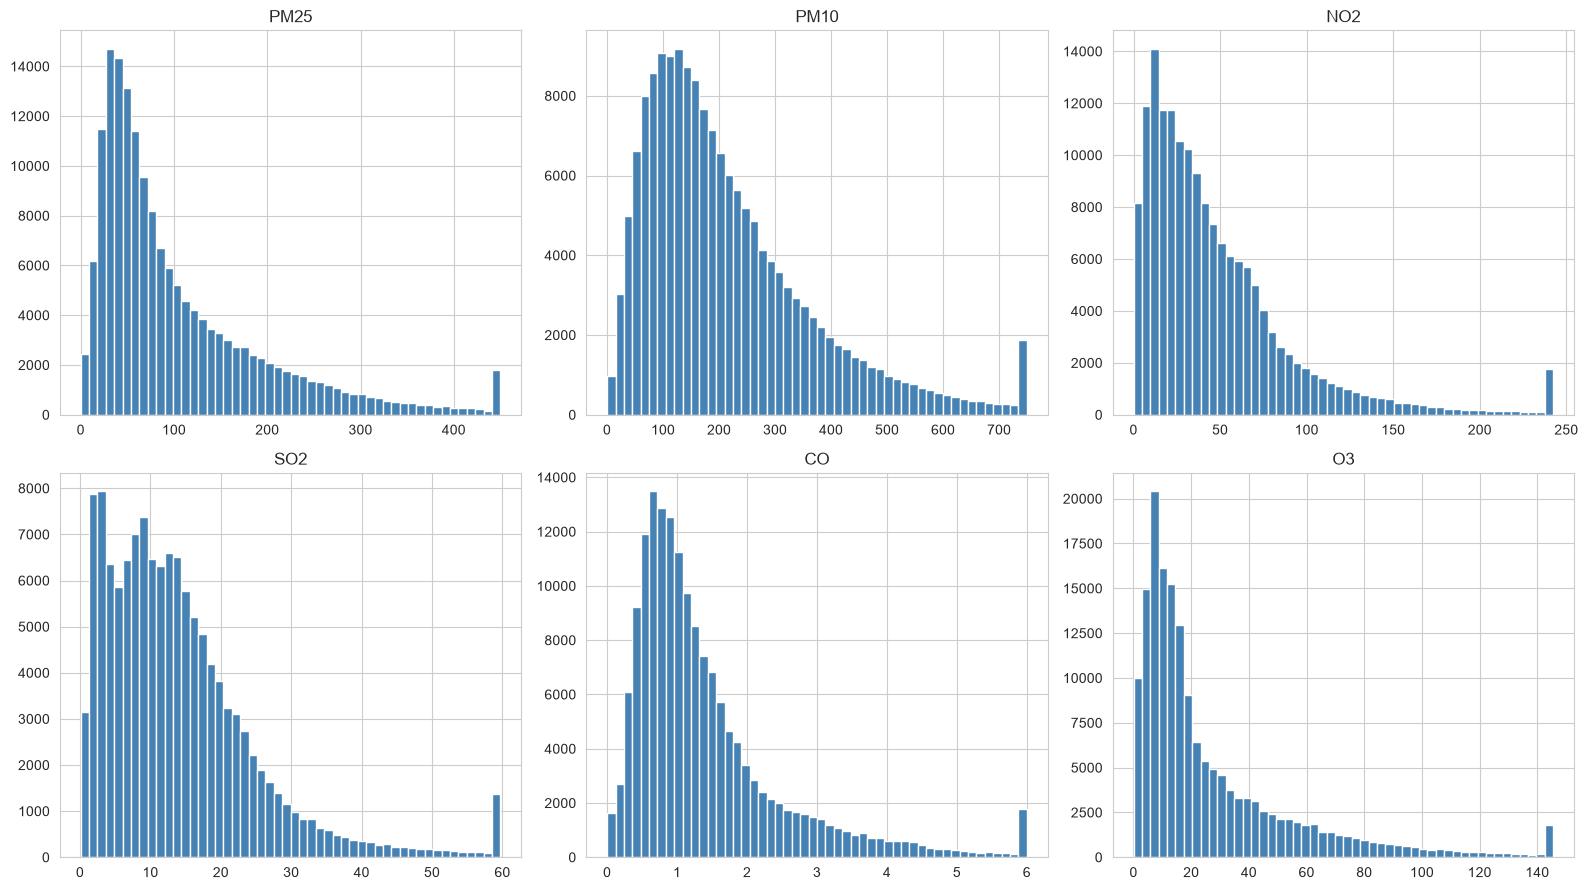

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
pollutants = ['PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3']
for ax, col in zip(axes.flat, pollutants):
    data = df[col].dropna()
    data = data.clip(upper=data.quantile(0.99))
    ax.hist(data, bins=50, color='steelblue', edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.show()

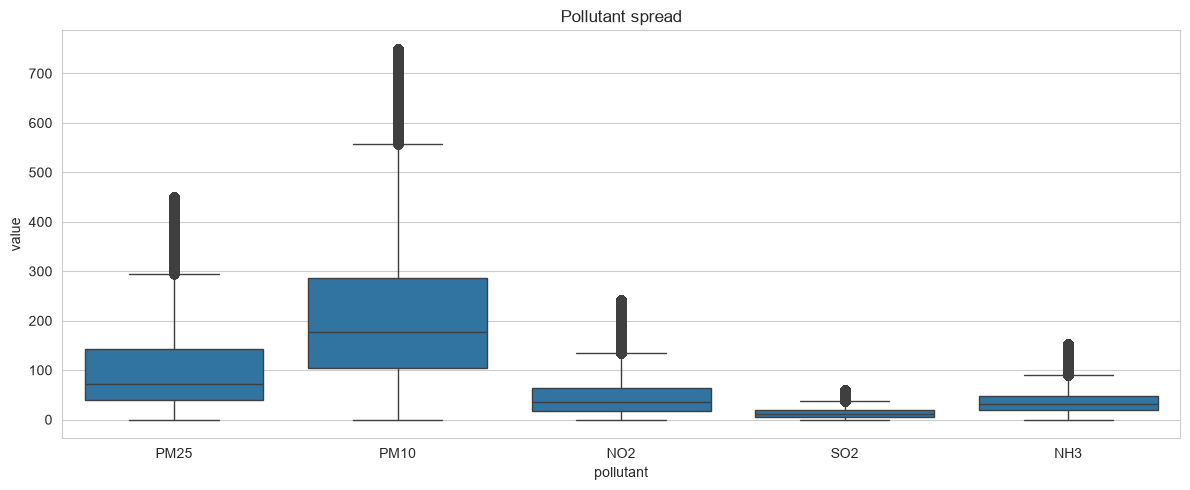

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_cols = ['PM25', 'PM10', 'NO2', 'SO2', 'NH3']
melted = df[plot_cols].melt(var_name='pollutant', value_name='value').dropna()
melted['value'] = melted.groupby('pollutant')['value'].transform(lambda x: x.clip(upper=x.quantile(0.99)))
sns.boxplot(data=melted, x='pollutant', y='value', ax=ax)
ax.set_title('Pollutant spread')
plt.tight_layout()
plt.show()

In [18]:
df[pollutants + ['NH3']].describe().T

,count,mean,std,min,25%,50%,75%,max
PM25,165937.0,106.040777,96.238120,0.01,40.30000,72.000,142.250,998.00
PM10,165376.0,216.358687,154.344788,0.21,105.25000,177.250,286.000,1000.00
NO2,164281.0,48.629087,48.118684,0.01,17.60000,35.825,64.180,499.20
SO2,128722.0,14.305987,12.564658,0.10,6.27125,11.950,18.750,198.50
CO,162896.0,1.414503,1.170028,0.00,0.68000,1.070,1.725,17.20
O3,166224.0,27.428698,31.124102,0.01,8.18250,15.800,35.600,498.92
NH3,131815.0,37.600396,29.986695,0.10,19.45000,30.650,47.470,495.80


## 5. Time-Series EDA — Trend & Seasonality

Delhi's pollution is strongly seasonal: winter (Oct–Feb) is dramatically worse than monsoon (Jul–Sep) due to temperature inversion, crop-residue (stubble) burning, and lower wind speeds trapping pollutants near the surface.

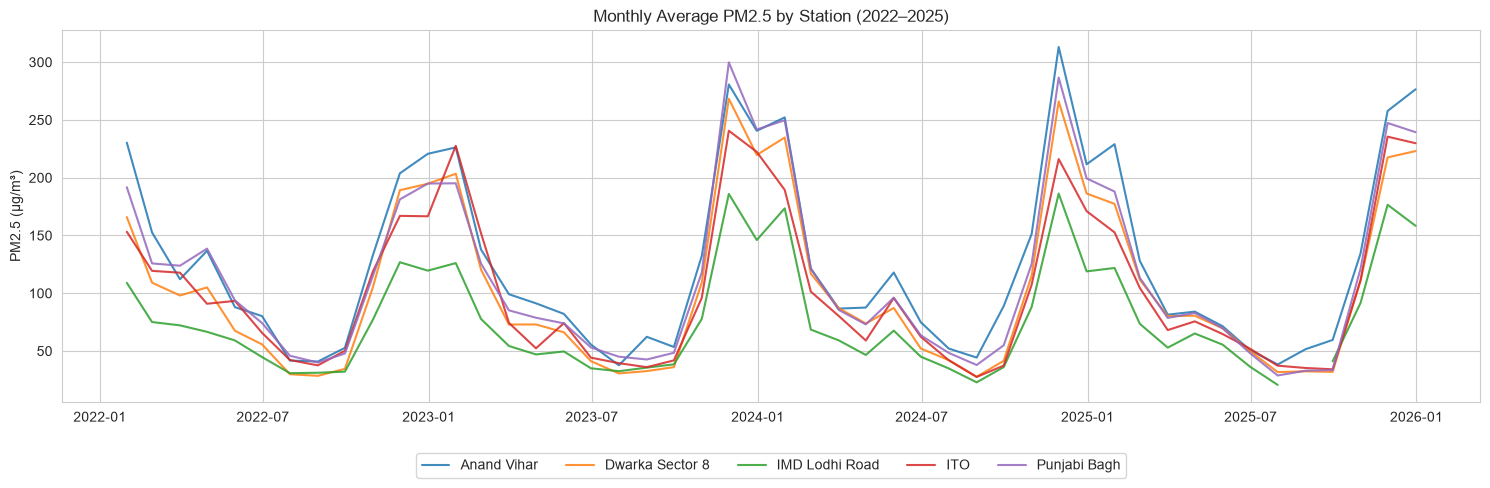

In [19]:
# Monthly average PM2.5 per station over the full 4 years
monthly = (df.set_index('timestamp')
             .groupby('station')['PM25']
             .resample('ME').mean()
             .reset_index())

fig, ax = plt.subplots(figsize=(15, 5))
for station, g in monthly.groupby('station'):
    ax.plot(g['timestamp'], g['PM25'], label=station, alpha=0.85)
ax.set_title('Monthly Average PM2.5 by Station (2022–2025)')
ax.set_ylabel('PM2.5 (µg/m³)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

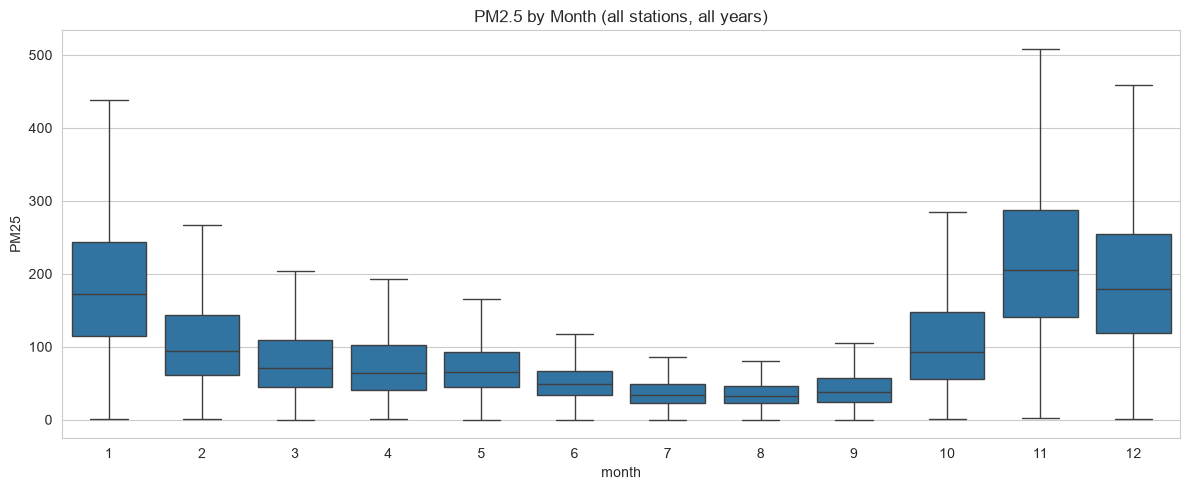

In [20]:
df['month'] = df['timestamp'].dt.month
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x='month', y='PM25', showfliers=False, ax=ax)
ax.set_title('PM2.5 by Month (all stations, all years)')
plt.tight_layout()
plt.show()

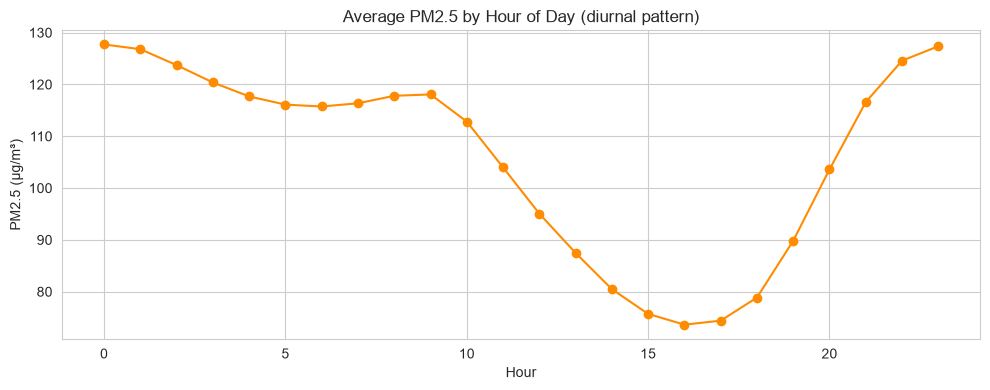

In [21]:
df['hour'] = df['timestamp'].dt.hour
hourly_avg = df.groupby('hour')['PM25'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
hourly_avg.plot(marker='o', ax=ax, color='darkorange')
ax.set_title('Average PM2.5 by Hour of Day (diurnal pattern)')
ax.set_xlabel('Hour')
ax.set_ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

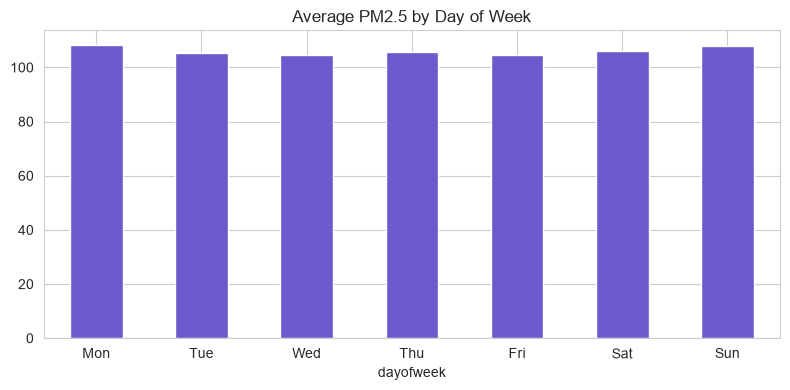

In [22]:
df['dayofweek'] = df['timestamp'].dt.dayofweek  # 0=Monday
dow_avg = df.groupby('dayofweek')['PM25'].mean()
fig, ax = plt.subplots(figsize=(8, 4))
dow_avg.plot(kind='bar', ax=ax, color='slateblue')
ax.set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], rotation=0)
ax.set_title('Average PM2.5 by Day of Week')
plt.tight_layout()
plt.show()

## 6. Station Comparison

In [23]:
station_avg = df.groupby('station')[pollutants].mean().sort_values('PM25', ascending=False)
station_avg

,PM25,PM10,NO2,SO2,CO,O3
station,,,,,,
Anand Vihar,128.829632,297.948056,76.404196,19.829968,2.016117,27.292143
Punjabi Bagh,116.274082,220.074357,42.737172,17.161636,1.104979,25.693825
Dwarka Sector 8,104.809820,239.140229,39.187706,7.415181,1.383096,27.998609
ITO,103.048283,164.541183,69.580717,13.669630,1.455512,25.567585
IMD Lodhi Road,77.765434,161.953785,15.777314,NaN,1.175194,30.670715


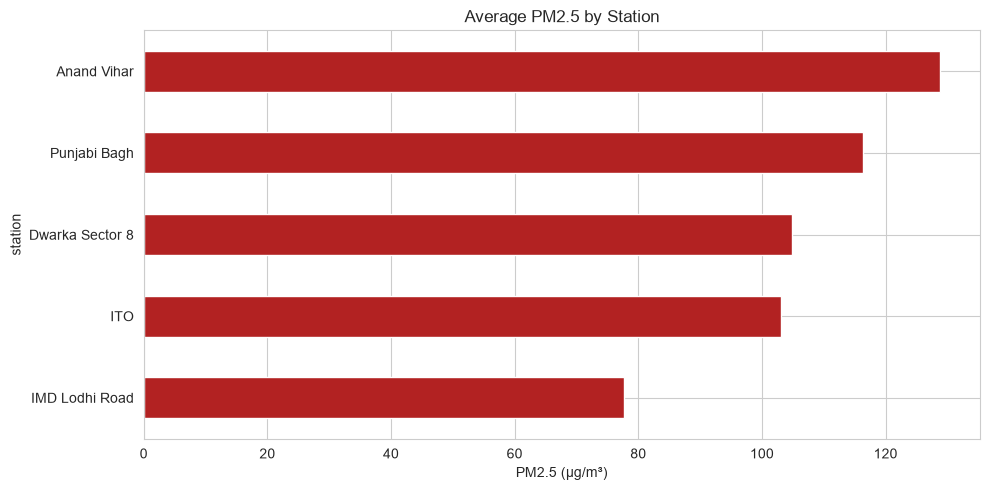

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
df.groupby('station')['PM25'].mean().sort_values().plot(kind='barh', ax=ax, color='firebrick')
ax.set_title('Average PM2.5 by Station')
ax.set_xlabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

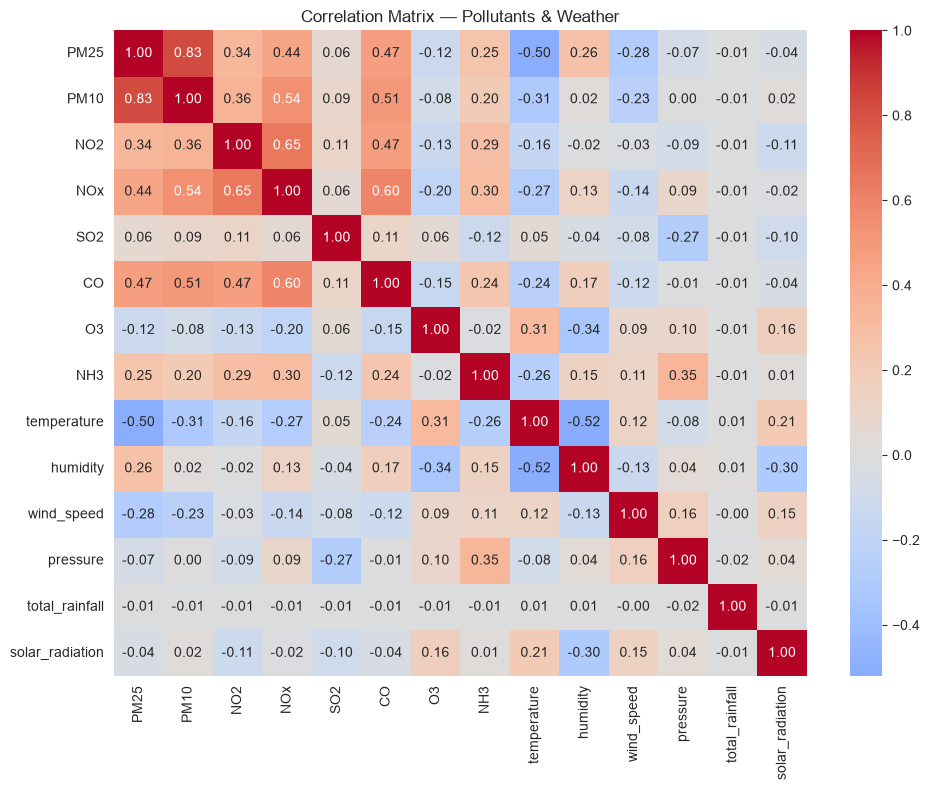

In [25]:
corr_cols = ['PM25', 'PM10', 'NO2', 'NOx', 'SO2', 'CO', 'O3', 'NH3',
             'temperature', 'humidity', 'wind_speed', 'pressure', 'total_rainfall','solar_radiation']
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Matrix — Pollutants & Weather')
plt.tight_layout()
plt.show()

**What to expect here:** PM2.5 and PM10 are almost always strongly correlated (same combustion/dust sources). Temperature and wind speed are typically *negatively* correlated with pollutant levels — calmer, colder air traps pollution near the ground, which is exactly why Delhi winters are so much worse.

## 8. Building the `AQI` Column

You asked how to make an AQI column — here's the standard, correct way to do it: use India's **CPCB National Air Quality Index (2014)** methodology rather than inventing a custom formula. This is what apps like SAFAR and the CPCB's own AQI app use, so your target will be interpretable and comparable to real-world numbers.

**How CPCB AQI works:**
1. For each pollutant, convert the concentration into a **sub-index (0–500)** using a *piecewise-linear* function between fixed breakpoints. For example, PM2.5 concentrations of 0–30 µg/m³ map linearly to a sub-index of 0–50 ("Good"), 30–60 map to 51–100 ("Satisfactory"), and so on up to "Severe" (401–500).
2. The formula for the sub-index of pollutant *p* is:

$$I_p = \frac{I_{Hi} - I_{Lo}}{BP_{Hi} - BP_{Lo}} (C_p - BP_{Lo}) + I_{Lo}$$

   where `C_p` is the (averaged) concentration, and `BP_Lo/BP_Hi`, `I_Lo/I_Hi` are the breakpoint bounds it falls between.
3. Sub-indices are computed on **averaged concentrations**, not raw instantaneous readings: a **24-hour rolling average** for PM2.5, PM10, NO2, SO2, NH3, and an **8-hour rolling average** for CO and O3.
4. The **overall AQI = the maximum of the available sub-indices** (the "worst pollutant" drives the number). CPCB requires **at least 3 pollutants**, with **at least one being PM2.5 or PM10**, otherwise AQI is undefined for that hour.

Since your data is hourly, using a *rolling* 24h/8h average (rather than a daily resample) gives you an AQI value **every hour** that updates as new readings come in — exactly what you want for an hourly forecasting problem, and it's how real-time AQI display panels compute a "live" AQI.

In [26]:
# CPCB breakpoint table: {pollutant: [(BP_lo, BP_hi, I_lo, I_hi), ...]}
# Units: PM2.5, PM10, NO2, SO2, NH3, O3 in µg/m3 ; CO in mg/m3
BREAKPOINTS = {
    'PM25': [(0,30,0,50), (30,60,50,100), (60,90,100,200), (90,120,200,300), (120,250,300,400), (250,500,400,500)],
    'PM10': [(0,50,0,50), (50,100,50,100), (100,250,100,200), (250,350,200,300), (350,430,300,400), (430,600,400,500)],
    'NO2':  [(0,40,0,50), (40,80,50,100), (80,180,100,200), (180,280,200,300), (280,400,300,400), (400,800,400,500)],
    'SO2':  [(0,40,0,50), (40,80,50,100), (80,380,100,200), (380,800,200,300), (800,1600,300,400), (1600,2100,400,500)],
    'CO':   [(0,1.0,0,50), (1.0,2.0,50,100), (2.0,10,100,200), (10,17,200,300), (17,34,300,400), (34,50,400,500)],
    'O3':   [(0,50,0,50), (50,100,50,100), (100,168,100,200), (168,208,200,300), (208,748,300,400), (748,1000,400,500)],
    'NH3':  [(0,200,0,50), (200,400,50,100), (400,800,100,200), (800,1200,200,300), (1200,1800,300,400), (1800,2400,400,500)],
}

def sub_index_vec(pollutant, series):
    """Vectorized CPCB sub-index calculation for a pandas Series of concentrations."""
    bps = BREAKPOINTS[pollutant]
    cap = bps[-1][1]
    s = series.clip(upper=cap)  # truncate extreme values to the top breakpoint, per CPCB convention
    result = pd.Series(np.nan, index=series.index)
    for bp_lo, bp_hi, i_lo, i_hi in bps:
        mask = (s >= bp_lo) & (s <= bp_hi) & s.notna()
        result[mask] = (i_hi - i_lo) / (bp_hi - bp_lo) * (s[mask] - bp_lo) + i_lo
    return result

def aqi_bucket(aqi):
    if pd.isna(aqi):
        return np.nan
    if aqi <= 50: return 'Good'
    if aqi <= 100: return 'Satisfactory'
    if aqi <= 200: return 'Moderate'
    if aqi <= 300: return 'Poor'
    if aqi <= 400: return 'Very Poor'
    return 'Severe'

print("Breakpoint tables and helper functions ready.")

Breakpoint tables and helper functions ready.


In [27]:
def compute_aqi(g):
    """Compute rolling-average sub-indices and overall AQI for a single station's
    time-sorted dataframe. Must be called per-station so averaging windows never
    mix readings from two different monitoring locations."""
    g = g.copy()

    # 24-hour rolling average (need at least 16 of the last 24 hours, per CPCB norm)
    for col in ['PM25', 'PM10', 'NO2', 'SO2', 'NH3']:
        g[f'{col}_24h'] = g[col].rolling(window=24, min_periods=16).mean()
    # 8-hour rolling average for CO and O3
    for col in ['CO', 'O3']:
        g[f'{col}_8h'] = g[col].rolling(window=8, min_periods=6).mean()

    sub_idx_cols = []
    for col in ['PM25', 'PM10', 'NO2', 'SO2', 'NH3']:
        g[f'I_{col}'] = sub_index_vec(col, g[f'{col}_24h'])
        sub_idx_cols.append(f'I_{col}')
    for col in ['CO', 'O3']:
        g[f'I_{col}'] = sub_index_vec(col, g[f'{col}_8h'])
        sub_idx_cols.append(f'I_{col}')

    n_available = g[sub_idx_cols].notna().sum(axis=1)
    has_pm = g[['I_PM25', 'I_PM10']].notna().any(axis=1)
    valid = (n_available >= 3) & has_pm

    g['AQI'] = np.where(valid, g[sub_idx_cols].max(axis=1), np.nan)
    g['AQI_Bucket'] = g['AQI'].apply(aqi_bucket)
    return g

# Process station-by-station (keeps each station's rolling windows independent)
processed = []
for station, g in df.groupby('station'):
    g = g.sort_values('timestamp').reset_index(drop=True)
    processed.append(compute_aqi(g))

df = pd.concat(processed, ignore_index=True)
df = df.sort_values(['station', 'timestamp']).reset_index(drop=True)

print("AQI computed for", df['AQI'].notna().sum(), f"of {len(df)} rows ({df['AQI'].notna().mean()*100:.1f}%)")
df[['station', 'timestamp', 'PM25', 'PM10', 'AQI', 'AQI_Bucket']].dropna(subset=['AQI']).head(10)

AQI computed for 167471 of 175320 rows (95.5%)


,station,timestamp,PM25,PM10,AQI,AQI_Bucket
15,Anand Vihar,2022-01-01 15:00:00,180.50,431.00,457.81875,Severe
16,Anand Vihar,2022-01-01 16:00:00,183.75,431.25,500.00000,Severe
17,Anand Vihar,2022-01-01 17:00:00,200.00,480.25,500.00000,Severe
18,Anand Vihar,2022-01-01 18:00:00,237.75,544.00,500.00000,Severe
19,Anand Vihar,2022-01-01 19:00:00,346.50,NaN,500.00000,Severe
20,Anand Vihar,2022-01-01 20:00:00,386.75,NaN,500.00000,Severe
21,Anand Vihar,2022-01-01 21:00:00,421.25,NaN,500.00000,Severe
22,Anand Vihar,2022-01-01 22:00:00,583.25,NaN,500.00000,Severe
23,Anand Vihar,2022-01-01 23:00:00,773.50,NaN,500.00000,Severe
24,Anand Vihar,2022-01-02 00:00:00,818.75,NaN,500.00000,Severe


In [28]:
df['AQI'].describe()

count    167471.000000
mean        220.542557
std         121.856505
min           8.368125
25%         114.583333
50%         188.923611
75%         325.571544
max         500.000000
Name: AQI, dtype: float64

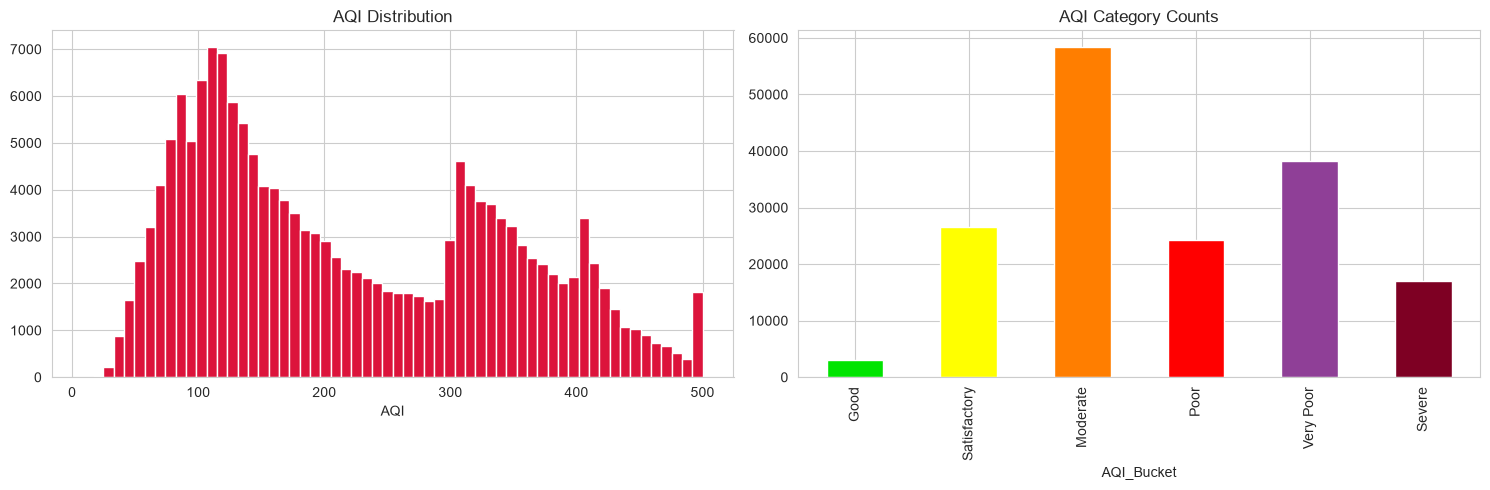

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df['AQI'].dropna().hist(bins=60, ax=axes[0], color='crimson', edgecolor='white')
axes[0].set_title('AQI Distribution')
axes[0].set_xlabel('AQI')

bucket_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
df['AQI_Bucket'].value_counts().reindex(bucket_order).plot(kind='bar', ax=axes[1],
    color=['#00e400','#ffff00','#ff7e00','#ff0000','#8f3f97','#7e0023'])
axes[1].set_title('AQI Category Counts')
plt.tight_layout()
plt.show()

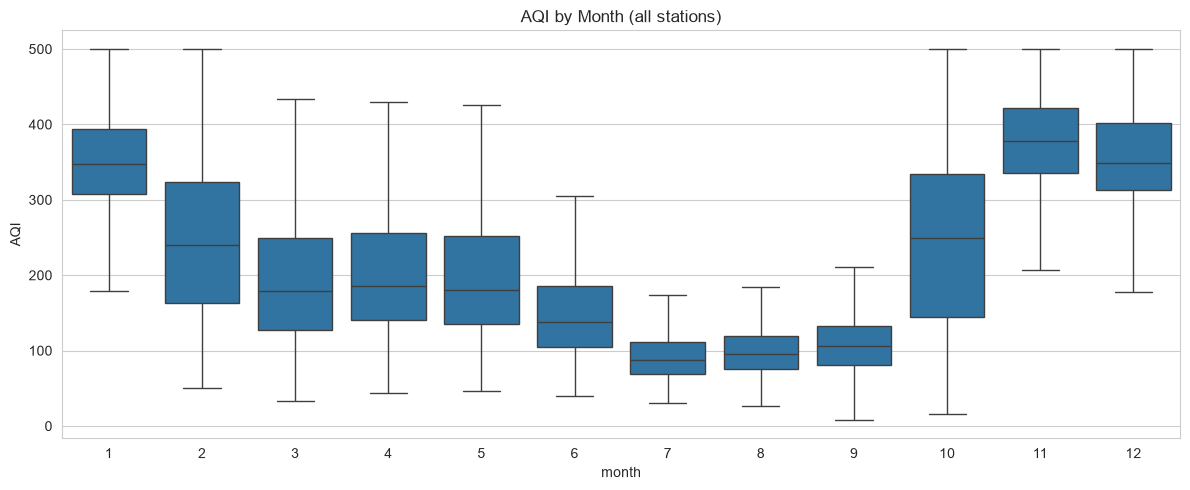

In [30]:
# AQI seasonality — confirms the winter smog pattern we saw for PM2.5
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x='month', y='AQI', showfliers=False, ax=ax)
ax.set_title('AQI by Month (all stations)')
plt.tight_layout()
plt.show()


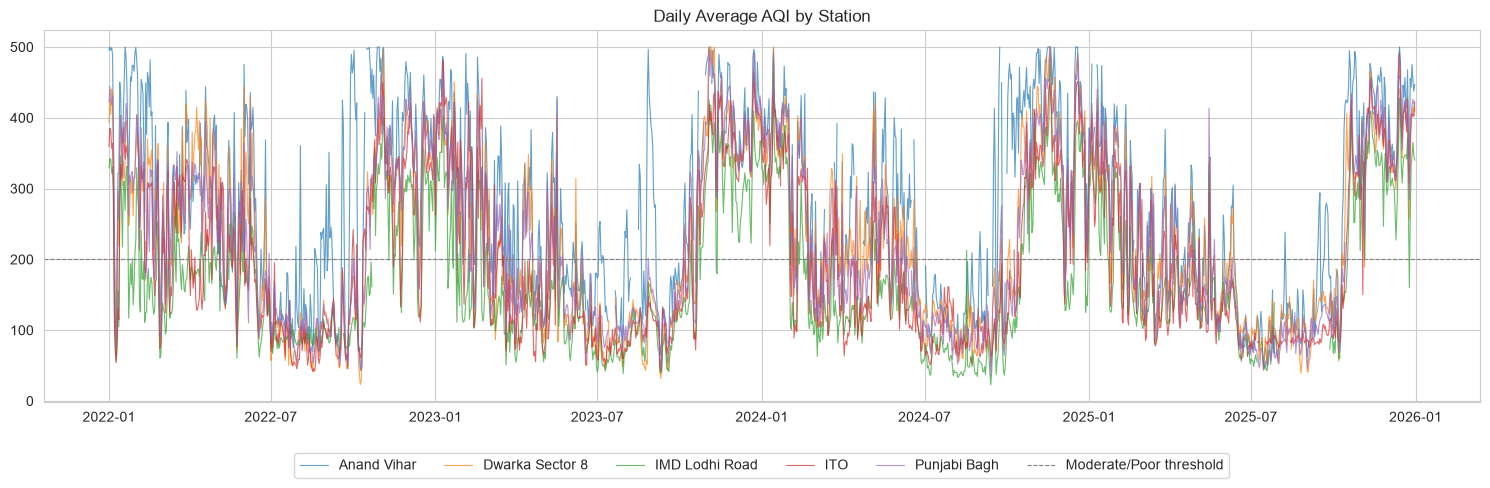

In [31]:
# AQI trend over time by station
daily_aqi = df.set_index('timestamp').groupby('station')['AQI'].resample('D').mean().reset_index()
fig, ax = plt.subplots(figsize=(15, 5))
for station, g in daily_aqi.groupby('station'):
    ax.plot(g['timestamp'], g['AQI'], label=station, alpha=0.7, linewidth=0.8)
ax.axhline(200, color='gray', linestyle='--', linewidth=0.8, label='Moderate/Poor threshold')
ax.set_title('Daily Average AQI by Station')
ax.legend(ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

> **Note on the 8 pollutants CPCB uses:** the official index also includes lead (Pb), which isn't in this dataset — that's fine, it's rarely available in real-time monitoring data anyway and CPCB's own methodology accounts for missing pollutants (minimum 3 of the available ones, incl. PM2.5/PM10).

## 9. Feature Engineering

Now we build the features you'll actually feed to a forecasting model. Everything below is computed **per station**, sorted by time — this is essential, because mixing rows from two different monitoring stations when computing a lag or rolling average would leak nonsense information (station A's pollution level 3 hours ago tells you nothing about station B).

We'll build four families of features:
- **Calendar / cyclical features** — hour, day of week, month, season, cyclical sin/cos encodings
- **Lag features** — the AQI/PM2.5/PM10 value N hours ago
- **Rolling window features** — trailing mean/std over various windows (computed on *shifted* data so the current row is never included — no leakage)
- **Rate-of-change features** — how fast AQI is rising or falling

### 9.1 Calendar & Cyclical Features

In [32]:
df['day'] = df['timestamp'].dt.day
df['dayofweek'] = df['timestamp'].dt.dayofweek      
df['month'] = df['timestamp'].dt.month
df['hour'] = df['timestamp'].dt.hour
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df["hour_of_week"] = (df["dayofweek"] * 24 +df["hour"])


def get_season(m):
    if m in [12, 1, 2]: return 'Winter'
    if m in [3, 4, 5, 6]: return 'Summer'
    if m in [7, 8, 9]: return 'Monsoon'
    return 'Post-Monsoon'

df['season'] = df['month'].apply(get_season)

# Delhi's pollution season (winter inversion + stubble burning): roughly Oct-Feb
df['is_pollution_season'] = df['month'].isin([10, 11, 12, 1, 2]).astype(int)
# Stubble-burning window (mid-Oct to mid-Nov) is when Punjab/Haryana crop-residue
# burning most sharply spikes Delhi's PM2.5 — flag it as its own feature
df['is_stubble_season'] = df['month'].isin([10, 11]).astype(int)

# Cyclical encodings so the model knows hour 23 and hour 0 are adjacent, not far apart
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['dow_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)
df["how_sin"] = np.sin(2 * np.pi * df["hour_of_week"] / 168)
df["how_cos"] = np.cos(2 * np.pi * df["hour_of_week"] / 168)

print("Calendar features added.")
df[['timestamp','hour','dayofweek','month','season','is_pollution_season','is_stubble_season','hour_of_week']].head()

Calendar features added.


,timestamp,hour,dayofweek,month,season,is_pollution_season,is_stubble_season,hour_of_week
0,2022-01-01 00:00:00,0,5,1,Winter,1,0,120
1,2022-01-01 01:00:00,1,5,1,Winter,1,0,121
2,2022-01-01 02:00:00,2,5,1,Winter,1,0,122
3,2022-01-01 03:00:00,3,5,1,Winter,1,0,123
4,2022-01-01 04:00:00,4,5,1,Winter,1,0,124


### 9.2 Lag Features (per station)

In [33]:
LAG_DAYS = [ 1,2,3,7,15,30]
LAG_TARGETS = ['AQI', 'PM25', 'PM10', 'NO2']

processed = []

for station, g in df.groupby('station'):
    g = g.sort_values('timestamp').reset_index(drop=True)

    for col in LAG_TARGETS:
        for days in LAG_DAYS:
            lag_days = days * 24
            g[f'{col}_lag_{days}d'] = g[col].shift(lag_days)

    processed.append(g)

df = pd.concat(processed, ignore_index=True)

df = df.sort_values(['station', 'timestamp']).reset_index(drop=True)

lag_cols_preview = [f'AQI_lag_{d}d' for d in LAG_DAYS]

df[['station', 'timestamp', 'AQI'] + lag_cols_preview].dropna().head()

,station,timestamp,AQI,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d
735,Anand Vihar,2022-01-31 15:00:00,500.0,493.468137,466.478328,471.061381,396.103239,367.457372,457.81875
736,Anand Vihar,2022-01-31 16:00:00,500.0,491.501225,469.280186,468.554987,391.518219,364.708974,500.00000
737,Anand Vihar,2022-01-31 17:00:00,500.0,490.312500,472.074303,466.419437,387.540486,362.721795,500.00000
738,Anand Vihar,2022-01-31 18:00:00,500.0,491.017157,475.216718,463.580563,385.981781,360.382051,500.00000
739,Anand Vihar,2022-01-31 19:00:00,500.0,490.441176,474.187307,465.006394,386.356275,356.856410,500.00000


### 9.3 Rolling Window Features (per station, leakage-free)

In [34]:
ROLL_WINDOWS = [3,7,15,30]
ROLL_TARGETS = ['AQI', 'PM25']

processed = []
for station, g in df.groupby('station'):
    g = g.sort_values('timestamp').reset_index(drop=True)
    for col in ROLL_TARGETS:
        # shift(1) FIRST so the rolling window never includes the current row's own value
        shifted = g[col].shift(1)
        for w in ROLL_WINDOWS:
            g[f'{col}_roll_mean_{w}d'] = shifted.rolling(window=w*24, min_periods=max(1, w // 3)).mean()
            g[f'{col}_roll_std_{w}d']  = shifted.rolling(window=w*24, min_periods=max(1, w // 3)).std()
            g[f'{col}_roll_min_{w}d']  = shifted.rolling(window=w*24, min_periods=max(1, w // 3)).min()
            g[f'{col}_roll_max_{w}d']  = shifted.rolling(window=w*24, min_periods=max(1, w // 3)).max()
    processed.append(g)

df = pd.concat(processed, ignore_index=True)
df = df.sort_values(['station', 'timestamp']).reset_index(drop=True)


df.dropna().head()

,timestamp,PM25,PM10,NO,NO2,NOx,NH3,SO2,CO,O3,Benzene,Toluene,temperature,humidity,wind_speed,wind_direction,total_rainfall,solar_radiation,pressure,source_file,station,city,month,hour,dayofweek,PM25_24h,PM10_24h,NO2_24h,SO2_24h,NH3_24h,CO_8h,O3_8h,I_PM25,I_PM10,I_NO2,I_SO2,I_NH3,I_CO,I_O3,AQI,AQI_Bucket,day,is_weekend,hour_of_week,season,is_pollution_season,is_stubble_season,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,how_sin,how_cos,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d,PM25_lag_1d,PM25_lag_2d,PM25_lag_3d,PM25_lag_7d,PM25_lag_15d,PM25_lag_30d,PM10_lag_1d,PM10_lag_2d,PM10_lag_3d,PM10_lag_7d,PM10_lag_15d,PM10_lag_30d,NO2_lag_1d,NO2_lag_2d,NO2_lag_3d,NO2_lag_7d,NO2_lag_15d,NO2_lag_30d,AQI_roll_mean_3d,AQI_roll_std_3d,AQI_roll_min_3d,AQI_roll_max_3d,AQI_roll_mean_7d,AQI_roll_std_7d,AQI_roll_min_7d,AQI_roll_max_7d,AQI_roll_mean_15d,AQI_roll_std_15d,AQI_roll_min_15d,AQI_roll_max_15d,AQI_roll_mean_30d,AQI_roll_std_30d,AQI_roll_min_30d,AQI_roll_max_30d,PM25_roll_mean_3d,PM25_roll_std_3d,PM25_roll_min_3d,PM25_roll_max_3d,PM25_roll_mean_7d,PM25_roll_std_7d,PM25_roll_min_7d,PM25_roll_max_7d,PM25_roll_mean_15d,PM25_roll_std_15d,PM25_roll_min_15d,PM25_roll_max_15d,PM25_roll_mean_30d,PM25_roll_std_30d,PM25_roll_min_30d,PM25_roll_max_30d
759,2022-02-01 15:00:00,198.00,532.50,55.05,77.35,85.55,52.30,23.08,1.05,21.42,4.35,36.45,18.72,55.10,0.32,265.00,0.0,422.95,973.08,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,15,1,309.114583,569.989130,63.336667,17.118750,41.221500,1.45500,23.09875,423.645833,482.346547,79.170833,21.398438,10.305375,72.75000,23.09875,482.346547,Severe,1,0,39,Winter,1,0,-0.707107,-7.071068e-01,0.866025,0.5,0.781831,0.623490,0.993712,1.119645e-01,500.000000,493.468137,466.478328,462.352941,410.907928,500.0,205.67,95.25,75.0,105.25,280.00,132.25,367.00,406.25,414.00,408.75,492.00,294.50,55.50,76.15,68.55,44.78,89.32,79.90,488.529650,12.435412,459.565217,500.0,475.218090,18.308900,438.566176,500.0,446.891368,55.750738,278.518056,500.0,394.431491,116.642153,75.0,500.0,270.009306,112.874593,70.25,565.5,242.952381,141.775427,40.75,841.5,244.833803,122.543656,40.75,841.5,222.499663,131.492586,14.0,841.5
762,2022-02-01 18:00:00,177.00,598.75,251.77,106.92,262.10,57.00,18.82,2.60,7.52,4.38,32.75,15.82,71.72,0.30,255.00,0.0,10.98,973.40,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,18,1,301.489583,589.750000,67.992917,16.897083,41.972857,1.51625,16.05750,420.595833,493.970588,84.991146,21.121354,10.493214,75.81250,16.05750,493.970588,Severe,1,0,42,Winter,1,0,-1.000000,-1.836970e-16,0.866025,0.5,0.781831,0.623490,1.000000,6.123234e-17,500.000000,491.017157,475.216718,469.466912,414.622762,500.0,255.00,127.00,74.5,147.00,296.00,199.25,437.50,610.25,581.50,509.75,530.25,642.75,63.72,130.50,119.10,75.18,107.95,134.82,489.236522,11.784324,459.565217,500.0,475.590382,18.319096,438.566176,500.0,447.514787,55.769752,278.518056,500.0,394.374168,116.593729,75.0,500.0,274.828750,106.554426,74.50,565.5,244.349702,140.829640,40.75,841.5,243.981690,122.587037,40.75,841.5,222.727924,131.384284,14.0,841.5
763,2022-02-01 19:00:00,210.25,659.00,215.75,100.55,229.02,59.70,19.68,2.95,6.70,6.55,43.98,15.30,76.92,0.30,262.75,0.0,9.08,973.08,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,19,1,298.916667,597.369565,69.673333,16.927500,42.778636,1.65000,14.88500,419.566667,498.452685,87.091667,21.159375,10.694659,82.50000,14.88500,498.452685,Severe,1,0,43,Winter,1,0,-0.965926,2.588190e-01,0.866025,0.5,0.781831,0.623490,0.999301,-3.739119e-02,500.000000,490.441176,474.187307,468.560049,413.772379,500.0,272.00,167.75,99.0,144.50,291.25,263.75,483.75,701.00,724.50,607.50,524.00,623.00,60.22,120.45,138.23,68.28,105.33,118.67,489.496992,11.676848,459.565217,500.0,475.736237,18.367533,438.566176,500.0,447.735198,55.796186,278.518056,500.0,394.365794,116.586349,75.0,500.0,276.252361,104.505271,94.00,565.5,244.528274,140.724442,40.75,841.5,243.6464

### 9.4 Rate-of-Change / Trend Features

In [35]:
    # is it rising or falling right now?
df['AQI_diff_1d'] = df['AQI'] - df['AQI_lag_1d']   # vs. same hour yesterday
df['AQI_diff_7d'] = df['AQI'] - df['AQI_lag_7d'] # vs. same hour last week

df['PM25_diff_1d'] = df['PM25'] - df['PM25_lag_1d']
df['PM25_diff_7d'] = df['PM25'] - df['PM25_lag_7d']
df['NO2_diff_1d'] = df['NO2'] - df['NO2_lag_1d']
df['NO2_diff_7d'] = df['NO2'] - df['NO2_lag_7d']


df.dropna().head()

,timestamp,PM25,PM10,NO,NO2,NOx,NH3,SO2,CO,O3,Benzene,Toluene,temperature,humidity,wind_speed,wind_direction,total_rainfall,solar_radiation,pressure,source_file,station,city,month,hour,dayofweek,PM25_24h,PM10_24h,NO2_24h,SO2_24h,NH3_24h,CO_8h,O3_8h,I_PM25,I_PM10,I_NO2,I_SO2,I_NH3,I_CO,I_O3,AQI,AQI_Bucket,day,is_weekend,hour_of_week,season,is_pollution_season,is_stubble_season,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,how_sin,how_cos,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d,PM25_lag_1d,PM25_lag_2d,PM25_lag_3d,PM25_lag_7d,PM25_lag_15d,PM25_lag_30d,PM10_lag_1d,PM10_lag_2d,PM10_lag_3d,PM10_lag_7d,PM10_lag_15d,PM10_lag_30d,NO2_lag_1d,NO2_lag_2d,NO2_lag_3d,NO2_lag_7d,NO2_lag_15d,NO2_lag_30d,AQI_roll_mean_3d,AQI_roll_std_3d,AQI_roll_min_3d,AQI_roll_max_3d,AQI_roll_mean_7d,AQI_roll_std_7d,AQI_roll_min_7d,AQI_roll_max_7d,AQI_roll_mean_15d,AQI_roll_std_15d,AQI_roll_min_15d,AQI_roll_max_15d,AQI_roll_mean_30d,AQI_roll_std_30d,AQI_roll_min_30d,AQI_roll_max_30d,PM25_roll_mean_3d,PM25_roll_std_3d,PM25_roll_min_3d,PM25_roll_max_3d,PM25_roll_mean_7d,PM25_roll_std_7d,PM25_roll_min_7d,PM25_roll_max_7d,PM25_roll_mean_15d,PM25_roll_std_15d,PM25_roll_min_15d,PM25_roll_max_15d,PM25_roll_mean_30d,PM25_roll_std_30d,PM25_roll_min_30d,PM25_roll_max_30d,AQI_diff_1d,AQI_diff_7d,PM25_diff_1d,PM25_diff_7d,NO2_diff_1d,NO2_diff_7d
759,2022-02-01 15:00:00,198.00,532.50,55.05,77.35,85.55,52.30,23.08,1.05,21.42,4.35,36.45,18.72,55.10,0.32,265.00,0.0,422.95,973.08,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,15,1,309.114583,569.989130,63.336667,17.118750,41.221500,1.45500,23.09875,423.645833,482.346547,79.170833,21.398438,10.305375,72.75000,23.09875,482.346547,Severe,1,0,39,Winter,1,0,-0.707107,-7.071068e-01,0.866025,0.5,0.781831,0.623490,0.993712,1.119645e-01,500.000000,493.468137,466.478328,462.352941,410.907928,500.0,205.67,95.25,75.0,105.25,280.00,132.25,367.00,406.25,414.00,408.75,492.00,294.50,55.50,76.15,68.55,44.78,89.32,79.90,488.529650,12.435412,459.565217,500.0,475.218090,18.308900,438.566176,500.0,446.891368,55.750738,278.518056,500.0,394.431491,116.642153,75.0,500.0,270.009306,112.874593,70.25,565.5,242.952381,141.775427,40.75,841.5,244.833803,122.543656,40.75,841.5,222.499663,131.492586,14.0,841.5,-17.653453,19.993606,-7.67,92.75,21.85,32.57
762,2022-02-01 18:00:00,177.00,598.75,251.77,106.92,262.10,57.00,18.82,2.60,7.52,4.38,32.75,15.82,71.72,0.30,255.00,0.0,10.98,973.40,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,18,1,301.489583,589.750000,67.992917,16.897083,41.972857,1.51625,16.05750,420.595833,493.970588,84.991146,21.121354,10.493214,75.81250,16.05750,493.970588,Severe,1,0,42,Winter,1,0,-1.000000,-1.836970e-16,0.866025,0.5,0.781831,0.623490,1.000000,6.123234e-17,500.000000,491.017157,475.216718,469.466912,414.622762,500.0,255.00,127.00,74.5,147.00,296.00,199.25,437.50,610.25,581.50,509.75,530.25,642.75,63.72,130.50,119.10,75.18,107.95,134.82,489.236522,11.784324,459.565217,500.0,475.590382,18.319096,438.566176,500.0,447.514787,55.769752,278.518056,500.0,394.374168,116.593729,75.0,500.0,274.828750,106.554426,74.50,565.5,244.349702,140.829640,40.75,841.5,243.981690,122.587037,40.75,841.5,222.727924,131.384284,14.0,841.5,-6.029412,24.503676,-78.00,30.00,43.20,31.74
763,2022-02-01 19:00:00,210.25,659.00,215.75,100.55,229.02,59.70,19.68,2.95,6.70,6.55,43.98,15.30,76.92,0.30,262.75,0.0,9.08,973.08,"raw_data_hourly_anand_vihar,_delhi_-_dpcc_1H 2...",Anand Vihar,Delhi,2,19,1,298.916667,597.369565,69.673333,16.927500,42.778636,1.65000,14.88500,419.566667,498.452685,87.091667,21.159375,10.694659,82.50000,14.88500,498.452685,Severe,1,0,43,Winter,1,0,-0.965926,2.588190e-01,0.866025,0.5,0.781831,0.623490,0.999301,-3.739119e-02,500.000000,490.441176,474.187307,468.560049,413.772379,500.0,272.00,167.75,99.0,144.50,291.25,263.75,483.75,701.00,724.50,607.50,524.00,623.00,60.22,120.45,138.23,68.28,105.33,118.67,489.496992,11.676848,459.565217,500.0,475.736237,18.367533,

### 9.5 Weather Lag/Rolling Features (where available)

In [36]:
# Weather drives dispersion — trailing wind speed / temperature are useful predictors
# where the sensor exists (recall: IMD Lodhi Road & ITO have no weather data, so these
# columns will be NaN for those two stations — that's expected, not a bug)
WEATHER_COLS = ['temperature', 'humidity', 'wind_speed', 'pressure', 'solar_radiation']

processed = []
for station, g in df.groupby('station'):
    g = g.sort_values('timestamp').reset_index(drop=True)
    for col in WEATHER_COLS:
        g[f'{col}_lag_1d'] = g[col].shift(24)
        g[f'{col}_roll_mean_1d'] = g[col].shift(1).rolling(window=24, min_periods=8).mean()
    processed.append(g)

df = pd.concat(processed, ignore_index=True)
df = df.sort_values(['station', 'timestamp']).reset_index(drop=True)
print("Weather lag/rolling features added.")

Weather lag/rolling features added.


### 9.6 Missing-Value Strategy After Feature Engineering

A few things happen naturally after all this feature engineering:
- The **first ~168 hours of each station's history** have `NaN` lag/rolling features (not enough history yet) — normal, and typically just dropped from training.
- **Tree-based models (LightGBM, XGBoost, CatBoost, Random Forest)** handle `NaN` natively — you usually don't need to impute anything for them.
- **Linear/neural models** need imputation. A reasonable default for AQI/pollutant gaps is: interpolate short gaps in time within each station, and use station-level median for anything left.

We'll do a light, transparent version here rather than silently mass-imputing everything.

In [37]:
# Interpolate short gaps (<=3 hours) in the raw pollutant/weather columns, per station,
# BEFORE they get used elsewhere -- this only smooths brief sensor dropouts, not long outages.
RAW_COLS_TO_INTERPOLATE = ['PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3',
                           'temperature', 'humidity', 'wind_speed', 'pressure','total_rainfall','solar_radiation']

processed = []
for station, g in df.groupby('station'):
    g = g.sort_values('timestamp').reset_index(drop=True)
    for col in RAW_COLS_TO_INTERPOLATE:
        g[col] = g[col].interpolate(method='linear', limit=3, limit_direction='both')
    processed.append(g)

df_interp = pd.concat(processed, ignore_index=True).sort_values(['station', 'timestamp']).reset_index(drop=True)

print("Missing % before vs after short-gap interpolation:")
compare = pd.DataFrame({
    'before': df[RAW_COLS_TO_INTERPOLATE].isna().mean() * 100,
    'after':  df_interp[RAW_COLS_TO_INTERPOLATE].isna().mean() * 100,
})
compare.round(2)

Missing % before vs after short-gap interpolation:


,before,after
PM25,5.35,3.15
PM10,5.67,3.47
NO2,6.30,4.35
SO2,26.58,23.36
CO,7.09,4.20
O3,5.19,3.07
NH3,24.81,22.81
temperature,42.03,41.25
humidity,42.01,41.24
wind_speed,42.12,41.35


> This notebook keeps `df` (uninterpolated) as the "source of truth" and shows `df_interp` separately so you can decide which to carry forward — re-run the AQI/lag/rolling cells on `df_interp` if you'd rather engineer features on the gap-filled series. For a first modeling pass, many people just keep `df` as-is and let a tree-based model handle the `NaN`s directly.

## 10. Final Feature Set & Export

In [ ]:
feature_cols = (
    ['station', 'timestamp', 'AQI', 'AQI_Bucket'] +
    ['hour', 'dayofweek', 'day', 'month', 'is_weekend', 'season',
     'is_pollution_season', 'is_stubble_season', 'hour_of_week',
     'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos','how_sin', 'how_cos'] +
    ['PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3'] +
    [f'AQI_lag_{h}d' for h in LAG_DAYS] +
    [f'PM25_lag_{h}d' for h in LAG_DAYS] +
    [f'PM10_lag_{h}d' for h in LAG_DAYS] +
    [f'NO2_lag_{h}d' for h in LAG_DAYS] +
    [f'AQI_roll_{stat}_{w}d' for stat in ['mean','std','min','max'] for w in ROLL_WINDOWS] +
    [f'PM25_roll_{stat}_{w}d' for stat in ['mean','std','min','max'] for w in ROLL_WINDOWS] +
    [ 'AQI_diff_1d', 'AQI_diff_7d', 'PM25_diff_1d','PM25_diff_7d', 'NO2_diff_1d', 'NO2_diff_7d'] +
    [f'{c}_lag_1d' for c in WEATHER_COLS] +
    [f'{c}_roll_mean_1d' for c in WEATHER_COLS]+
    [f'{c}' for c in WEATHER_COLS]+
    ['total_rainfall']
)

final_df = df[feature_cols].copy()
print("Final engineered dataset shape:", final_df.shape)
final_df.head()

Final engineered dataset shape: (175320, 106)


,station,timestamp,AQI,AQI_Bucket,hour,dayofweek,day,month,is_weekend,season,is_pollution_season,is_stubble_season,hour_of_week,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,how_sin,how_cos,PM25,PM10,NO2,SO2,CO,O3,NH3,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d,PM25_lag_1d,PM25_lag_2d,PM25_lag_3d,PM25_lag_7d,PM25_lag_15d,PM25_lag_30d,PM10_lag_1d,PM10_lag_2d,PM10_lag_3d,PM10_lag_7d,PM10_lag_15d,PM10_lag_30d,NO2_lag_1d,NO2_lag_2d,NO2_lag_3d,NO2_lag_7d,NO2_lag_15d,NO2_lag_30d,AQI_roll_mean_3d,AQI_roll_mean_7d,AQI_roll_mean_15d,AQI_roll_mean_30d,AQI_roll_std_3d,AQI_roll_std_7d,AQI_roll_std_15d,AQI_roll_std_30d,AQI_roll_min_3d,AQI_roll_min_7d,AQI_roll_min_15d,AQI_roll_min_30d,AQI_roll_max_3d,AQI_roll_max_7d,AQI_roll_max_15d,AQI_roll_max_30d,PM25_roll_mean_3d,PM25_roll_mean_7d,PM25_roll_mean_15d,PM25_roll_mean_30d,PM25_roll_std_3d,PM25_roll_std_7d,PM25_roll_std_15d,PM25_roll_std_30d,PM25_roll_min_3d,PM25_roll_min_7d,PM25_roll_min_15d,PM25_roll_min_30d,PM25_roll_max_3d,PM25_roll_max_7d,PM25_roll_max_15d,PM25_roll_max_30d,AQI_diff_1d,AQI_diff_7d,PM25_diff_1d,PM25_diff_7d,NO2_diff_1d,NO2_diff_7d,temperature_lag_1d,humidity_lag_1d,wind_speed_lag_1d,pressure_lag_1d,solar_radiation_lag_1d,temperature_roll_mean_1d,humidity_roll_mean_1d,wind_speed_roll_mean_1d,pressure_roll_mean_1d,solar_radiation_roll_mean_1d,temperature,humidity,wind_speed,pressure,solar_radiation,total_rainfall
0,Anand Vihar,2022-01-01 00:00:00,NaN,NaN,0,5,1,1,1,Winter,1,0,120,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521,-0.974928,-0.222521,613.25,NaN,104.50,17.80,NaN,5.38,30.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.95,84.15,0.3,974.98,8.95,0.0
1,Anand Vihar,2022-01-01 01:00:00,NaN,NaN,1,5,1,1,1,Winter,1,0,121,0.258819,0.965926,0.5,0.866025,-0.974928,-0.222521,-0.982566,-0.185912,684.00,892.0,73.82,10.95,NaN,0.30,68.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,613.250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,613.25,NaN,NaN,NaN,613.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.52,87.62,0.3,974.90,8.88,0.0
2,Anand Vihar,2022-01-01 02:00:00,NaN,NaN,2,5,1,1,1,Winter,1,0,122,0.500000,0.866025,0.5,0.866025,-0.974928,-0.222521,-0.988831,-0.149042,615.25,916.5,66.70,8.80,NaN,6.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,648.625,648.625,NaN,NaN,50.027805,50.027805,NaN,NaN,613.25,613.25,NaN,NaN,684.00,684.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.38,89.38,0.3,974.78,8.88,0.0
3,Anand Vihar,2022-01-01 03:00:00,NaN,NaN,3,5,1,1,1,Winter,1,0,123,0.707107,0.707107,0.5,0.866025,-0.974928,-0.222521,-0.993712,-0.111964,739.00,950.0,70.25,5.67,NaN,6.90,64.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,637.500,637.500,NaN,NaN,40.282595,40.282595,NaN,NaN,613.25,613.25,NaN,NaN,684.00,684.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.15,90.65,0.3,974.90,8.90,0.0
4,Anand Vihar,2022-01-01 04:00:00,NaN,NaN,4,5,1,1,1,Winter,1,0,124,0.866025,0.500000,0.5,0.866025,-0.974928,-0.222521,-0.997204,-0.074730,596.50,801.5,60.12,12.28,NaN,10.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,662.875,662.875,NaN,NaN,60.476063,60.476063,NaN,NaN,613.25,613.25,NaN,NaN,739.00,739.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.05,91.32,0.3,974.68,8.8

In [39]:
final_df.to_csv('delhi_aqi_features.csv', index=False)
print("Saved delhi_aqi_features.csv")

Saved delhi_aqi_features.csv


## 11. Train/Test Split for Forecasting

**Do not use a random train/test split for time-series forecasting** — it leaks future information into the training set (a random split can put "yesterday" in test and "today" in train, which a lag feature would then cheat with). Split **chronologically** instead.

**Careful with the weather columns here.** Remember from Section 2: `IMD Lodhi Road` and `ITO` have no weather sensor data at all, so `*_lag_24h`/`*_roll_mean_24h` for temperature/humidity/wind/pressure are `NaN` for **every row** of those two stations — not just the first week. If you naively `dropna()` across *all* lag/rolling columns including weather, you silently lose those two stations entirely (40% of your data). We drop rows based on the **AQI/PM lag+rolling columns only** (which just need "enough history", true for all 5 stations after the first week) and handle weather missingness separately.

In [40]:
aqi_pm_lag_roll_cols = [c for c in final_df.columns if ('lag' in c or 'roll' in c) and c not in
                        [f'{w}_lag_1d' for w in WEATHER_COLS] + [f'{w}_roll_mean_1d' for w in WEATHER_COLS]]

# Simple chronological holdout: last ~3 months as test, rest as train
model_df = final_df.dropna(subset=['AQI']).copy()      # rows without a valid AQI target
model_df = model_df.dropna(subset=aqi_pm_lag_roll_cols)  # need enough AQI/PM25/PM10 history

print("Stations remaining after AQI/PM history requirement:")
print(model_df['station'].value_counts())
print()
print("Weather feature coverage (these 2 stations have none — decide whether to drop the")
print("weather columns to keep all 5 stations, or restrict to the 3 stations that have them):")
print(model_df.groupby('station')['temperature_lag_1d'].apply(lambda x: x.notna().mean() * 100))

cutoff = model_df['timestamp'].max() - pd.Timedelta(days=90)
train = model_df[model_df['timestamp'] < cutoff]
test  = model_df[model_df['timestamp'] >= cutoff]

print(f"\nTrain: {train.shape}  ({train['timestamp'].min()} to {train['timestamp'].max()})")
print(f"Test:  {test.shape}  ({test['timestamp'].min()} to {test['timestamp'].max()})")

Stations remaining after AQI/PM history requirement:
station
Dwarka Sector 8    26819
IMD Lodhi Road     24466
ITO                22459
Punjabi Bagh       21188
Anand Vihar        15253
Name: count, dtype: int64

Weather feature coverage (these 2 stations have none — decide whether to drop the
weather columns to keep all 5 stations, or restrict to the 3 stations that have them):
station
Anand Vihar        99.567298
Dwarka Sector 8    99.955256
IMD Lodhi Road      0.000000
ITO                 0.000000
Punjabi Bagh       99.806494
Name: temperature_lag_1d, dtype: float64

Train: (102216, 106)  (2022-01-31 15:00:00 to 2025-10-02 22:00:00)
Test:  (7969, 106)  (2025-10-02 23:00:00 to 2025-12-31 23:00:00)


In [41]:
# For more robust validation than a single holdout, use walk-forward CV via
# sklearn's TimeSeriesSplit -- each fold trains on the past and validates on the
# immediately-following period, then the window slides forward.
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
station_sample = model_df[model_df['station'] == model_df['station'].iloc[0]].sort_values('timestamp')

for fold, (train_idx, val_idx) in enumerate(tscv.split(station_sample)):
    tr_dates = station_sample.iloc[train_idx]['timestamp']
    va_dates = station_sample.iloc[val_idx]['timestamp']
    print(f"Fold {fold}: train up to {tr_dates.max().date()}  |  validate {va_dates.min().date()} to {va_dates.max().date()}")

Fold 0: train up to 2022-09-21  |  validate 2022-09-21 to 2023-03-16
Fold 1: train up to 2023-03-16  |  validate 2023-03-16 to 2024-01-09
Fold 2: train up to 2024-01-09  |  validate 2024-01-09 to 2024-12-24
Fold 3: train up to 2024-12-24  |  validate 2024-12-24 to 2025-08-01
Fold 4: train up to 2025-08-01  |  validate 2025-08-01 to 2025-12-31


## 12. Summary & Next Steps

**What this notebook produced:**
- A cleaned, gap-checked hourly dataset across 5 Delhi stations (2022–2025)
- An `AQI` column built with the official CPCB methodology (24h/8h rolling sub-indices, max-of-available-pollutants rule), plus an `AQI_Bucket` category
- A rich feature set: calendar/cyclical features, multi-horizon lag features (1h–1 week), leakage-free rolling statistics, rate-of-change features, and weather lag/rolling features
- `delhi_aqi_features.csv` — ready to feed into a model
- A correct chronological train/test split + `TimeSeriesSplit` walk-forward validation setup

**Suggested next steps for the forecasting model itself:**
1. **Baseline first:** predict `AQI_lag_1h` (persistence — "next hour = same as now") and measure its error. Any real model needs to beat this.
2. **Gradient boosting (LightGBM/XGBoost/CatBoost)** on the engineered feature set is usually the strongest, easiest starting point for tabular hourly forecasting, and handles `NaN` natively.
3. Treat `station` as a categorical feature (or train separate models per station if their dynamics differ a lot — Anand Vihar and IMD Lodhi Road look quite different in the EDA above).
4. For multi-step-ahead forecasts (e.g. next 24h), either train a **separate model per horizon** (t+1h, t+6h, t+24h, ...) or use a **recursive** approach that feeds each prediction back in as the next step's lag feature.
5. If you want to capture more complex temporal dependencies, an **LSTM/GRU** or **Temporal Fusion Transformer** is worth trying once the gradient-boosting baseline is in place — but start simple.